### Filter composites

In this notebook we study what is changing of the detected atmospheric blocking

In [1]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import statistics
from tqdm import tqdm


#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [2]:
%cd /Users/michelefilippucci/Data/ERA5/
!ls

/Users/michelefilippucci/Data/ERA5
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_clim_snowc_0.1x0.1_1980-2000.nc
ERA5_geopotential_day_2.5x2.5_500hPa_1950-2021.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_daily_1959-2021.nc
ERA5_ta_mon_r144x73_19790101-20191231.nc
ERA5_ymonmean_snowc_0.1x0.1_1980-2000.nc
dictionaries
prepare_dataset.ipynb
snow_cover_ERA5_0.1x0.1_1980-2000.nc
ta
ua
va


In [3]:
#IMPORT DATASET
ds = xr.load_dataset('ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960.nc')
#store variables for the composite
unfilt = ds['DAV_tracked']
kept = ds['DAV_tracked']
zg = ds['zg']/9.8
lat = ds['lat']
lon = ds['lon']


dic = np.load('dictionaries/ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960_DIC.npy',allow_pickle=True)
dic = dic[1:-1]
#FILTERED LABELS
lab_filt = []
time_filt = []
duration_filt = []
lat_pos = 45
for i,event in enumerate(dic):
  if i>0 and 4 < event['persistence'] < 25 and 500000 < event['avg_area'] < 4e6 and event['avg_dist_traveled'] < 600: #Correction due to Bologna Mistake
    lab_filt.append(i)
    time_filt.append(event['date'])
    duration_filt.append(event['persistence'])
#UNFILTERED LABELS
lab_base = []
time_base = []
duration_base = []
lat_pos = 45
for i,event in enumerate(dic):
  if i>0:
    try:
      lat_pos = sum(event['track'][0])/len(event['track'][0])
    except:
      print(i,event)
  if i>0 and 4 < event['persistence'] < 25 and 500000 < event['avg_area'] < 4e6 and i not in lab_filt:
    lab_base.append(i)
    time_base.append(event['date'])
    duration_base.append(event['persistence'])


print(len(lab_filt),len(lab_base))

ds.close()

557 192


In [4]:
print(lab_base)

[29, 48, 59, 65, 115, 158, 178, 236, 278, 369, 409, 426, 456, 533, 584, 615, 799, 830, 849, 978, 989, 1013, 1014, 1022, 1028, 1075, 1182, 1316, 1371, 1421, 1430, 1460, 1536, 1562, 1606, 1754, 1876, 1910, 2019, 2064, 2074, 2103, 2216, 2227, 2241, 2276, 2299, 2356, 2377, 2407, 2411, 2431, 2450, 2518, 2519, 2547, 2563, 2572, 2664, 2675, 2710, 2746, 2757, 2778, 2808, 2827, 2933, 2976, 2990, 2997, 3017, 3018, 3030, 3111, 3116, 3143, 3171, 3204, 3242, 3248, 3312, 3317, 3392, 3552, 3591, 3610, 3635, 3671, 3694, 3775, 3788, 3795, 3807, 3827, 3891, 3967, 3973, 4005, 4021, 4069, 4071, 4229, 4261, 4263, 4294, 4320, 4344, 4384, 4386, 4442, 4462, 4489, 4550, 4558, 4625, 4637, 4775, 4776, 4829, 4912, 4962, 5016, 5061, 5089, 5133, 5151, 5177, 5218, 5280, 5290, 5379, 5414, 5429, 5433, 5473, 5492, 5507, 5519, 5579, 5626, 5713, 5795, 5826, 5857, 5881, 5904, 5996, 6035, 6040, 6051, 6206, 6223, 6289, 6291, 6313, 6398, 6473, 6535, 6617, 6661, 6693, 6734, 6743, 6750, 6864, 6873, 6952, 7031, 7089, 7106, 7127

In [5]:
#compute the two composites
plon,plat = -35,70 #Greenland Blocking
#plon,plat = 10,55 #European Blocking

#COMP EXCLUDED
series_unf = unfilt.loc[:,plat,plon]
list_unf = []
for t in tqdm(range(len(zg[:,0,0]))):
    if any(lab_base == series_unf[t].values):
        #print(ciao)
        idx = lab_base.index(series_unf[t].values)
        tmp = zg.loc[time_base[idx]:time_base[idx]+np.timedelta64(duration_base[idx],'D'),:,:].mean('time').values
        list_unf.append(tmp)
sum_unf = sum(list_unf)
var_unf = sum([((x - sum_unf/len(list_unf)) ** 2) for x in list_unf])/len(list_unf)
std_unf = var_unf**0.5

#COMP KEPT
series_kpt = kept.loc[:,plat,plon]
list_kpt = []
for t in tqdm(range(len(zg[:,0,0]))):
    if any(lab_filt == series_kpt[t].values):
        idx = lab_filt.index(series_kpt[t].values)
        tmp = zg.loc[time_filt[idx]:time_filt[idx]+np.timedelta64(duration_filt[idx],'D'),:,:].mean('time').values
        list_kpt.append(tmp)
sum_kpt = sum(list_kpt)
var_kpt = sum([((x - sum_kpt/len(list_kpt)) ** 2) for x in list_kpt])/len(list_kpt)
std_kpt = var_kpt**0.5

100%|█████████████████████████████████████████████████████████████████| 4018/4018 [00:00<00:00, 9103.25it/s]


In [6]:
print(len(list_kpt),len(list_unf))

27 3


/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:451: UserWarning: The .xlabels_top attribute is deprecated. Please use .top_labels to toggle visibility instead.
  warnings.warn('The .xlabels_top attribute is deprecated. Please '
/Users/michelefilippucci/miniconda3/envs/blocktoolbox_env/lib/python3.11/site-packages/cartopy/mpl/gridliner.py:475: UserWarning: The .ylabels_left attribute is deprecated. Please use .left_labels to toggle visibility instead.
  warnings.warn('The .ylabels_left attribute is deprecated. Please '


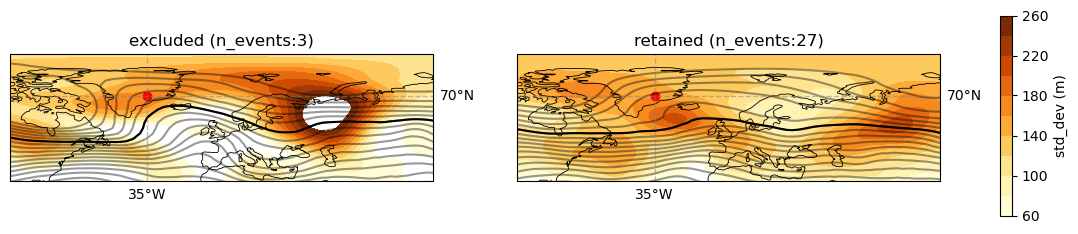

In [7]:
import matplotlib.ticker as mticker

fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(12,4),subplot_kw={'projection': ccrs.PlateCarree()})
ax.flatten()
title1 = "excluded (n_events:" + str(len(list_unf))+')'
title2 = "retained (n_events:" + str(len(list_kpt))+')'
titles = (title1,title2)

#plot composite
for i,field in enumerate(((sum_unf)/len(list_unf),sum_kpt/len(list_kpt))):
    field = ma.masked_array(field,field==0)
    extent =[-100,100,30,90] #Greenland
    #extent =[-40,60,20,90] #Europe
    #extent = [-180,180,30,90] #NH   
    ax[i].set_extent(extent, ccrs.PlateCarree())
    ax[i].coastlines(linewidth = 0.6)
    ax[i].plot(plon,plat,'or')
    gl = ax[i].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')
    gl.xlocator = mticker.FixedLocator([plon])
    gl.ylocator = mticker.FixedLocator([plat])
    gl.xlabels_top = False
    gl.ylabels_left = False
    '''
    cont = ax[i].contourf(lon,lat,field,
                          cmap = 'Spectral_r',
                          levels = np.arange(5200,6000,40),
                          extent=[0,90,-180,180],
                          extend = 'both')
                          #cmap = "YlGnBu")
    '''
    cont_thick = ax[i].contour(lon,lat,field,
                         colors = 'black',
                         levels = [5400],
                         extent=[0,90,-180,180])
    cont = ax[i].contour(lon,lat,field,
                        colors = 'black',
                        alpha =0.4,
                        levels = np.arange(5200,6000,40),
                        extent=[0,90,-180,180],
                        )
                        #cmap = "YlGnBu")
    
    ax[i].set_title(titles[i])# + " (" + str(plon) + "E," + str(plat) + "W)")
        

#plot variance

for i,field in enumerate((std_unf,std_kpt)):
    std = ax[i].contourf(lon,lat,field,
                        cmap = 'YlOrBr',
                        alpha = 1,
                        levels = np.arange(60,280,20))    

cbar_ax = fig.add_axes([0.95,0.25,0.01,0.5])
cbar = plt.colorbar(std, cax=cbar_ax, orientation='vertical',label="std_dev (m)",pad=0.08, aspect=60)


plt.savefig("/Users/michelefilippucci/PLOTS/blocking poster/composites.png",bbox_inches='tight',dpi = 400)
